In [ ]:
import tensorflow as tf
from tensorflow.keras import layers,Model

In [ ]:
def unet_model(input_size=(256,256,3), num_classes=3):
    inputs = layers.Input(input_size)

    # Encoder

    conv1 = layers.Conv2D(64,(3,3), activation='relu', padding='same')(inputs)
    conv1 = layers.Conv2D(64,(3,3), activation='relu', padding='same')(conv1)
    pool1 = layers.MaxPooling2D(pool_size=(2,2))(conv1)

    conv2 = layers.Conv2D(128,(3,3), activation='relu', padding='same')(pool1)
    conv2 = layers.Conv2D(128,(3,3), activation='relu', padding='same')(conv2)
    pool2 = layers.MaxPooling2D(pool_size=(2,2))(conv2)

    conv3 = layers.Conv2D(256,(3,3), activation='relu', padding='same')(pool2)
    conv3 = layers.Conv2D(256,(3,3), activation='relu', padding='same')(conv3)
    pool3 = layers.MaxPooling2D(pool_size=(2,2))(conv3)

    conv4 = layers.Conv2D(512,(3,3), activation='relu', padding='same')(pool3)
    conv4 = layers.Conv2D(512,(3,3), activation='relu', padding='same')(conv4)
    pool4 = layers.MaxPooling2D(pool_size=(2,2))(conv4)

    # Bottleneck

    conv5 = layers.Conv2D(1024,(3,3), activation='relu', padding='same')(pool4)
    conv5 = layers.Conv2D(1024,(3,3), activation='relu', padding='same')(conv5)

    #  Decoder

    up6 = layers.Conv2DTranspose(512, (2,2), strides=(2,2), padding='same')(conv5)
    merge6 = layers.concatenate([up6, conv4])
    conv6 = layers.Conv2D(512,(3,3), activation='relu', padding='same')(merge6)
    conv6 = layers.Conv2D(512,(3,3), activation='relu', padding='same')(conv6)

    up7 = layers.Conv2DTranspose(256, (2,2), strides=(2,2), padding='same')(conv6)
    merge7 = layers.concatenate([up7, conv3])
    conv7 = layers.Conv2D(256,(3,3), activation='relu', padding='same')(merge7)
    conv7 = layers.Conv2D(256,(3,3), activation='relu', padding='same')(conv7)

    up8 = layers.Conv2DTranspose(128, (2,2), strides=(2,2), padding='same')(conv7)
    merge8 = layers.concatenate([up8, conv2])
    conv8 = layers.Conv2D(128,(3,3), activation='relu', padding='same')(merge8)
    conv8 = layers.Conv2D(128,(3,3), activation='relu', padding='same')(conv8)

    up9 = layers.Conv2DTranspose(64, (2,2), strides=(2,2), padding='same')(conv8)
    merge9 = layers.concatenate([up9, conv1])
    conv9 = layers.Conv2D(64,(3,3), activation='relu', padding='same')(merge9)
    conv9 = layers.Conv2D(64,(3,3), activation='relu', padding='same')(conv9)

    # Output layer
    outputs = layers.Conv2D(num_classes, (1,1), activation='softmax')(conv9)

    model = Model(inputs=[inputs], outputs=[outputs])

    model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

    return model

/usr/local/lib/python3.12/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


1/1 ━━━━━━━━━━━━━━━━━━━━ 9s 9s/step


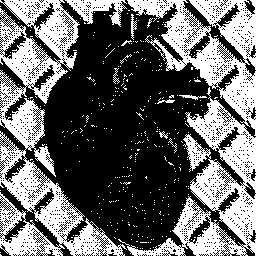

In [ ]:
import numpy as np
from PIL import Image
from tensorflow.keras.preprocessing import image

# Load the image
img = Image.open('/content/heart.png')

# Convert to RGB to ensure 3 channels, even if the original is grayscale
img = img.convert('RGB')

# Preprocess the image
img = img.resize((256,256))
img_array = image.img_to_array(img)
img_array = np.expand_dims(img_array, axis=0) # Add batch dimension, now that it's already 3 channels
img_array = img_array / 255.

# Load the model
model = unet_model(input_size=(256,256,3), num_classes=2)

# Make predictions
predictions = model.predict(img_array)

# Convert predictions to a numpy array and resize to original image size
predictions = np.squeeze(predictions, axis=0)
predictions = np.argmax(predictions, axis=-1)
predictions = Image.fromarray(np.uint8(predictions*255))
predictions = predictions.resize((img.width, img.height))

predictions

In [ ]:
import tensorflow as tf
import tensorflow_datasets as tfds

# Load dataset
dataset, info = tfds.load(
    'oxford_iiit_pet:4.0.0',
    with_info=True,
    as_supervised=True
)

train_data = dataset['train']
test_data = dataset['test']

print("Dataset loaded successfully")
print(info)

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/2 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/oxford_iiit_pet/incomplete.W25BCI_4.0.0/oxford_iiit_pet-train.tfrecord*...…

Generating test examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/oxford_iiit_pet/incomplete.W25BCI_4.0.0/oxford_iiit_pet-test.tfrecord*...:…

Dataset oxford_iiit_pet downloaded and prepared to /root/tensorflow_datasets/oxford_iiit_pet/4.0.0. Subsequent calls will reuse this data.
Dataset loaded successfully
tfds.core.DatasetInfo(
    name='oxford_iiit_pet',
    full_name='oxford_iiit_pet/4.0.0',
    description="""
    The Oxford-IIIT pet dataset is a 37 category pet image dataset with roughly 200
    images for each class. The images have large variations in scale, pose and
    lighting. All images have an associated ground truth annotation of breed and
    species. Additionally, head bounding boxes are provided for the training split,
    allowing using this dataset for simple object detection tasks. In the test
    split, the bounding boxes are empty.
    """,
    homepage='http://www.robots.ox.ac.uk/~vgg/data/pets/',
    data_dir='/root/tensorflow_datasets/oxford_iiit_pet/4.0.0',
    file_format=tfrecord,
    download_size=773.52 MiB,
    dataset_size=773.68 MiB,
    features=FeaturesDict({
        'file_name': Text(shap

In [ ]:
IMG_SIZE = 256
BATCH_SIZE = 8

# Re-load the dataset without as_supervised=True to access segmentation_mask
dataset_raw, info = tfds.load(
    'oxford_iiit_pet:4.0.0',
    with_info=True
)

def format_example(element):
    image = element['image']
    mask = element['segmentation_mask']
    return image, mask

# Apply the format_example to get (image, mask) pairs
train_data = dataset_raw['train'].map(format_example)
test_data = dataset_raw['test'].map(format_example)

def preprocess(image, mask):
    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))
    image = image / 255.0

    mask = tf.image.resize(mask, (IMG_SIZE, IMG_SIZE), method='nearest')
    mask = tf.cast(mask, tf.int32) - 1  # labels start from 0

    return image, mask

train_data = train_data.map(preprocess).shuffle(1000).batch(BATCH_SIZE)
test_data = test_data.map(preprocess).batch(BATCH_SIZE)

print("Preprocessing complete")

Preprocessing complete


In [ ]:
from tensorflow.keras import layers, Model

def unet_model(input_size=(256,256,3), num_classes=3):
    inputs = layers.Input(input_size)

    # Encoder
    c1 = layers.Conv2D(64,3,activation='relu',padding='same')(inputs)
    c1 = layers.Conv2D(64,3,activation='relu',padding='same')(c1)
    p1 = layers.MaxPooling2D()(c1)

    c2 = layers.Conv2D(128,3,activation='relu',padding='same')(p1)
    c2 = layers.Conv2D(128,3,activation='relu',padding='same')(c2)
    p2 = layers.MaxPooling2D()(c2)

    c3 = layers.Conv2D(256,3,activation='relu',padding='same')(p2)
    c3 = layers.Conv2D(256,3,activation='relu',padding='same')(c3)
    p3 = layers.MaxPooling2D()(c3)

    c4 = layers.Conv2D(512,3,activation='relu',padding='same')(p3)
    c4 = layers.Conv2D(512,3,activation='relu',padding='same')(c4)
    p4 = layers.MaxPooling2D()(c4)

    # Bottleneck
    c5 = layers.Conv2D(1024,3,activation='relu',padding='same')(p4)
    c5 = layers.Conv2D(1024,3,activation='relu',padding='same')(c5)

    # Decoder
    u6 = layers.Conv2DTranspose(512,2,strides=2,padding='same')(c5)
    u6 = layers.concatenate([u6,c4])
    c6 = layers.Conv2D(512,3,activation='relu',padding='same')(u6)
    c6 = layers.Conv2D(512,3,activation='relu',padding='same')(c6)

    u7 = layers.Conv2DTranspose(256,2,strides=2,padding='same')(c6)
    u7 = layers.concatenate([u7,c3])
    c7 = layers.Conv2D(256,3,activation='relu',padding='same')(u7)
    c7 = layers.Conv2D(256,3,activation='relu',padding='same')(c7)

    u8 = layers.Conv2DTranspose(128,2,strides=2,padding='same')(c7)
    u8 = layers.concatenate([u8,c2])
    c8 = layers.Conv2D(128,3,activation='relu',padding='same')(u8)
    c8 = layers.Conv2D(128,3,activation='relu',padding='same')(c8)

    u9 = layers.Conv2DTranspose(64,2,strides=2,padding='same')(c8)
    u9 = layers.concatenate([u9,c1])
    c9 = layers.Conv2D(64,3,activation='relu',padding='same')(u9)
    c9 = layers.Conv2D(64,3,activation='relu',padding='same')(c9)

    outputs = layers.Conv2D(num_classes,1,activation='softmax')(c9)

    model = Model(inputs, outputs)

    model.compile(
        optimizer='adam',
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    return model

model = unet_model()
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_19 (Conv2D)  │ (None, 256, 256,  │      1,792 │ input_layer_1[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_20 (Conv2D)  │ (None, 256, 256,  │     36,928 │ conv2d_19[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_4     │ (None, 128, 128,  │          0 │ conv2d_20[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_21 (Conv2D)  │ (None, 128, 128,  │     73,856 │ max_pooling2d_4[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_22 (Conv2D)  │ (None, 128, 128,  │    147,584 │ conv2d_21[0][0]   │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_5     │ (None, 64, 64,    │          0 │ conv2d_22[0][0]   │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_23 (Conv2D)  │ (None, 64, 64,    │    295,168 │ max_pooling2d_5[… │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_24 (Conv2D)  │ (None, 64, 64,    │    590,080 │ conv2d_23[0][0]   │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_6     │ (None, 32, 32,    │          0 │ conv2d_24[0][0]   │
│ (MaxPooling2D)      │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_25 (Conv2D)  │ (None, 32, 32,    │  1,180,160 │ max_pooling2d_6[… │
│                     │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_26 (Conv2D)  │ (None, 32, 32,    │  2,359,808 │ conv2d_25[0][0]   │
│                     │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_7     │ (None, 16, 16,    │          0 │ conv2d_26[0][0]   │
│ (MaxPooling2D)      │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_27 (Conv2D)  │ (None, 16, 16,    │  4,719,616 │ max_pooling2d_7[… │
│                     │ 1024)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_28 (Conv2D)  │ (None, 16, 16,    │  9,438,208 │ conv2d_27[0][0]   │
│                     │ 1024)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose_4  │ (None, 32, 32,    │  2,097,664 │ conv2d_28[0][0]   │
│ (Conv2DTranspose)   │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_4       │ (None, 32, 32,    │          0 │ conv2d_transpose

 Total params: 31,031,875 (118.38 MB)

 Trainable params: 31,031,875 (118.38 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
EPOCHS = 10

history = model.fit(
    train_data,
    validation_data=test_data,
    epochs=EPOCHS
)

Epoch 1/10
460/460 ━━━━━━━━━━━━━━━━━━━━ 405s 750ms/step - accuracy: 0.6192 - loss: 0.8716 - val_accuracy: 0.7097 - val_loss: 0.7140
Epoch 2/10
460/460 ━━━━━━━━━━━━━━━━━━━━ 323s 694ms/step - accuracy: 0.7185 - loss: 0.7002 - val_accuracy: 0.7096 - val_loss: 0.7102
Epoch 3/10
460/460 ━━━━━━━━━━━━━━━━━━━━ 323s 694ms/step - accuracy: 0.7224 - loss: 0.6829 - val_accuracy: 0.7273 - val_loss: 0.6734
Epoch 4/10
460/460 ━━━━━━━━━━━━━━━━━━━━ 325s 699ms/step - accuracy: 0.7319 - loss: 0.6609 - val_accuracy: 0.7371 - val_loss: 0.6502
Epoch 5/10
460/460 ━━━━━━━━━━━━━━━━━━━━ 323s 695ms/step - accuracy: 0.7459 - loss: 0.6339 - val_accuracy: 0.7581 - val_loss: 0.6143
Epoch 6/10
460/460 ━━━━━━━━━━━━━━━━━━━━ 322s 692ms/step - accuracy: 0.7744 - loss: 0.5744 - val_accuracy: 0.7827 - val_loss: 0.5584
Epoch 7/10
460/460 ━━━━━━━━━━━━━━━━━━━━ 322s 692ms/step - accuracy: 0.8049 - loss: 0.5011 - val_accuracy: 0.7141 - val_loss: 0.6452
Epoch 8/10
460/460 ━━━━━━━━━━━━━━━━━━━━ 324s 697ms/step - accuracy: 0.8290 -

In [ ]:
def mean_iou(y_true, y_pred):
    y_pred = tf.argmax(y_pred, axis=-1)
    y_pred = tf.cast(y_pred, tf.int32)

    intersection = tf.reduce_sum(tf.cast(y_true == y_pred, tf.float32))
    union = tf.cast(tf.size(y_true), tf.float32)

    return intersection / union

for images, masks in test_data.take(1):
    preds = model.predict(images)
    iou_score = mean_iou(masks, preds)
    print("IoU:", iou_score.numpy())

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
IoU: 0.0


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 258ms/step


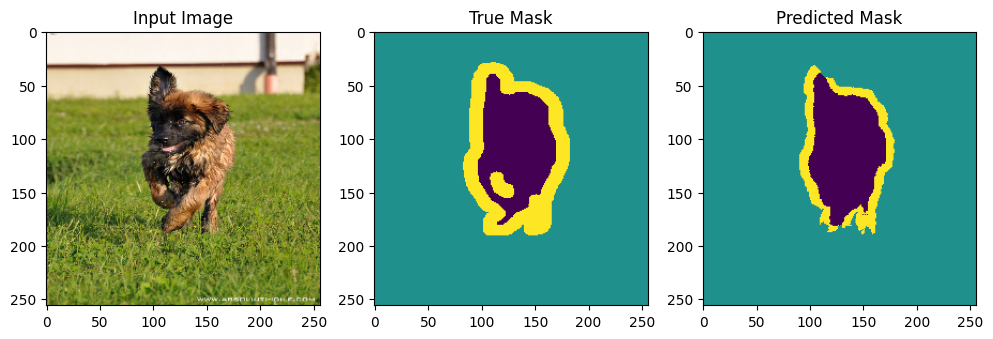

In [ ]:
import matplotlib.pyplot as plt

def display_sample(image, mask, pred_mask):
    plt.figure(figsize=(12,4))

    plt.subplot(1,3,1)
    plt.title("Input Image")
    plt.imshow(image)

    plt.subplot(1,3,2)
    plt.title("True Mask")
    plt.imshow(tf.squeeze(mask))

    plt.subplot(1,3,3)
    plt.title("Predicted Mask")
    plt.imshow(pred_mask)

    plt.show()

for images, masks in test_data.take(1):
    preds = model.predict(images)
    pred_mask = tf.argmax(preds[0], axis=-1)
    display_sample(images[0], masks[0], pred_mask)

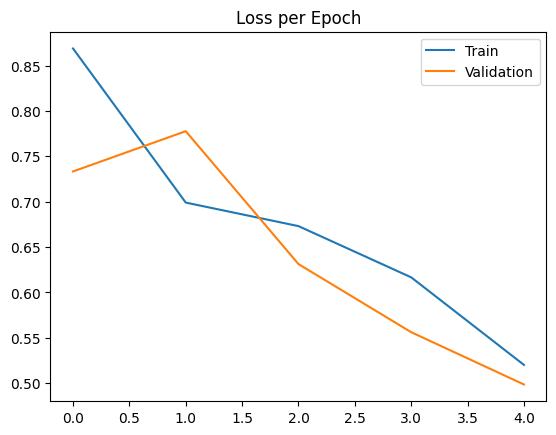

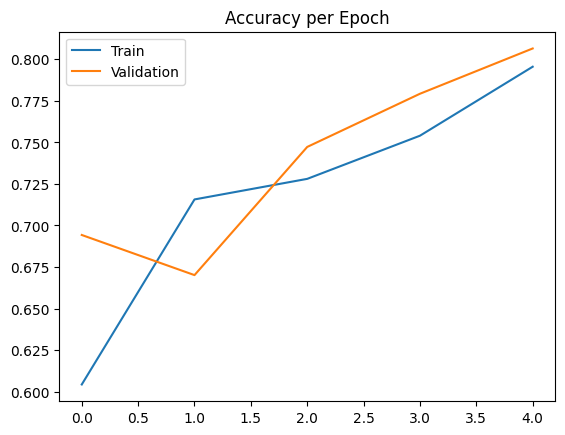

In [ ]:
plt.figure()
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title("Loss per Epoch")
plt.legend(["Train","Validation"])
plt.show()

plt.figure()
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title("Accuracy per Epoch")
plt.legend(["Train","Validation"])
plt.show()

In [ ]:
import numpy as np
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

all_preds = []
all_true = []

for images, masks in test_data:
    preds = model.predict(images)
    preds = tf.argmax(preds, axis=-1)

    # Flatten
    all_preds.append(tf.reshape(preds, [-1]).numpy())
    all_true.append(tf.reshape(masks, [-1]).numpy())

# Concatenate everything
all_preds = np.concatenate(all_preds)
all_true = np.concatenate(all_true)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 288ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 245ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 345ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 229ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 205ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 266ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 307ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 274ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 225ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 178ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 179ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 177ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 177ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 180ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 178ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 184ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 187ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 180ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 189ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 189ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 197ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 193ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 193ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 200ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 204ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 

In [ ]:
cm = confusion_matrix(all_true, all_preds)

print("Confusion Matrix:\n")
print(cm)

Confusion Matrix:

[[ 53222519  16248939   2641506]
 [  3954851 133923833    908218]
 [  6089916  16693186   6768616]]


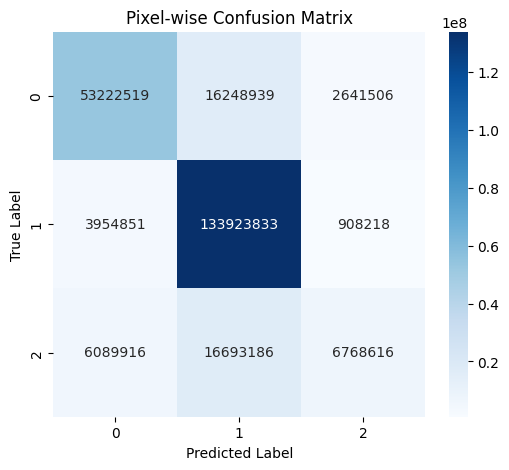

In [ ]:
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Pixel-wise Confusion Matrix")
plt.show()